In [2]:
%pip uninstall -y gradio gradio-client diffusers

Found existing installation: gradio 6.31.0
Uninstalling gradio-6.31.0:
  Successfully uninstalled gradio-6.31.0
Found existing installation: gradio_client 2.7.2
Uninstalling gradio_client-2.7.2:
  Successfully uninstalled gradio_client-2.7.2
Found existing installation: diffusers 0.42.1
Uninstalling diffusers-0.42.1:
  Successfully uninstalled diffusers-0.42.1


In [3]:

%pip install -q \
    "transformers>=4.51.0,<5" \
    "datasets>=3.0,<5" \
    "accelerate>=1.0" \
    "bitsandbytes>=0.45" \
    "huggingface-hub>=0.34,<1" \
    "pandas==2.2.3" \
    "numpy==2.2.6" \
    "pyarrow==23.0.1" \
    "scikit-learn" \
    "tqdm" \
    "safetensors"


In [4]:
# Verify the GPU and import


import torch
import transformers
import datasets
import pandas as pd
import numpy as np

print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("Datasets:", datasets.__version__)
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)

assert torch.cuda.is_available(), "Enable GPU in Colab."

print("GPU:", torch.cuda.get_device_name(0))

gpu_gb = (
    torch.cuda.get_device_properties(0).total_memory
    / 1024**3
)

print(f"GPU memory: {gpu_gb:.2f} GB")


PyTorch: 2.14.1+cu130
Transformers: 4.57.6
Datasets: 4.8.5
Pandas: 2.2.3
NumPy: 2.4.6
GPU: Tesla T4
GPU memory: 14.56 GB


In [5]:
# Mounting Google Drive and DEFINING the configuration


from google.colab import drive
from pathlib import Path
import random
import json
import hashlib
import re

drive.mount("/content/drive")

PROJECT_DIR = Path(
    "/content/drive/MyDrive/clinical-qa-finetuning-v2"
)

DATA_DIR = PROJECT_DIR / "data"
RESULTS_DIR = PROJECT_DIR / "results" / "baseline"
MODELS_DIR = PROJECT_DIR / "models"

for directory in [DATA_DIR, RESULTS_DIR, MODELS_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

MODEL_ID = "Qwen/Qwen3-4B"
MEDQA_ID = "GBaker/MedQA-USMLE-4-options"
PUBMEDQA_ID = "qiaojin/PubMedQA"

MEDQA_TARGET = 10_000
PUBMEDQA_TARGET = 2_000
BASELINE_SAMPLES = 50

print("Project:", PROJECT_DIR)


Mounted at /content/drive
Project: /content/drive/MyDrive/clinical-qa-finetuning-v2


In [8]:

from datasets import load_dataset

MEDQA_ID = "GBaker/MedQA-USMLE-4-options"

medqa = load_dataset(MEDQA_ID)

print("Original dataset:")
print(medqa)

assert "train" in medqa
assert "test" in medqa

# Create validation from the original training split
if "validation" in medqa:
    medqa_train_raw = medqa["train"]
    medqa_val_raw = medqa["validation"]

elif "dev" in medqa:
    medqa_train_raw = medqa["train"]
    medqa_val_raw = medqa["dev"]

else:
    print("\nNo validation split found.")
    print("Creating 500-question validation split...")

    split = medqa["train"].train_test_split(
        test_size=500,
        seed=SEED,
        shuffle=True
    )

    medqa_train_raw = split["train"]
    medqa_val_raw = split["test"]

medqa_test_raw = medqa["test"]

print("\nFinal MedQA splits:")
print("Train:", len(medqa_train_raw))
print("Validation:", len(medqa_val_raw))
print("Test:", len(medqa_test_raw))

print("\nTraining example:")
print(medqa_train_raw[0])


Original dataset:
DatasetDict({
    train: Dataset({
        features: ['question', 'answer', 'options', 'meta_info', 'answer_idx', 'metamap_phrases'],
        num_rows: 10178
    })
    test: Dataset({
        features: ['question', 'answer', 'options', 'meta_info', 'answer_idx', 'metamap_phrases'],
        num_rows: 1273
    })
})

No validation split found.
Creating 500-question validation split...

Final MedQA splits:
Train: 9678
Validation: 500
Test: 1273

Training example:
{'question': 'A researcher is studying physiologic and hormonal changes that occur during pregnancy. Specifically, they examine the behavior of progesterone over the course of the menstrual cycle and find that it normally decreases over time; however, during pregnancy this decrease does not occur in the usual time frame. The researcher identifies a circulating factor that appears to be responsible for this difference in progesterone behavior. In order to further examine this factor, the researcher denatures the

In [10]:
# Loading the PubMedQA Data


pubmed_artificial = load_dataset(
    PUBMEDQA_ID,
    "pqa_artificial",
    split="train"
)

pubmed_labeled = load_dataset(
    PUBMEDQA_ID,
    "pqa_labeled",
    split="train"
)

print("Artificial examples:", len(pubmed_artificial))
print("Human-labeled examples:", len(pubmed_labeled))

print("\nArtificial example:")
print(pubmed_artificial[0])

print("\nHuman-labeled example:")
print(pubmed_labeled[0])


README.md: 0.00B [00:00, ?B/s]

pqa_artificial/train-00000-of-00001.parq(…):   0%|          | 0.00/233M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/211269 [00:00<?, ? examples/s]

pqa_labeled/train-00000-of-00001.parquet:   0%|          | 0.00/1.08M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/1000 [00:00<?, ? examples/s]

Artificial examples: 211269
Human-labeled examples: 1000

Artificial example:
{'pubid': 25429730, 'question': 'Are group 2 innate lymphoid cells ( ILC2s ) increased in chronic rhinosinusitis with nasal polyps or eosinophilia?', 'context': {'contexts': ['Chronic rhinosinusitis (CRS) is a heterogeneous disease with an uncertain pathogenesis. Group 2 innate lymphoid cells (ILC2s) represent a recently discovered cell population which has been implicated in driving Th2 inflammation in CRS; however, their relationship with clinical disease characteristics has yet to be investigated.', 'The aim of this study was to identify ILC2s in sinus mucosa in patients with CRS and controls and compare ILC2s across characteristics of disease.', 'A cross-sectional study of patients with CRS undergoing endoscopic sinus surgery was conducted. Sinus mucosal biopsies were obtained during surgery and control tissue from patients undergoing pituitary tumour resection through transphenoidal approach. ILC2s were 

In [11]:
# Load Official tes IDS


import requests

TEST_IDS_URL = (
    "https://raw.githubusercontent.com/"
    "pubmedqa/pubmedqa/master/data/"
    "test_ground_truth.json"
)

response = requests.get(TEST_IDS_URL, timeout=30)
response.raise_for_status()

official_test_answers = response.json()

official_test_ids = set(
    str(pubid) for pubid in official_test_answers
)

assert len(official_test_ids) == 500, (
    "Unexpected PubMedQA official test-set size."
)

labeled_ids = set(
    str(row["pubid"]) for row in pubmed_labeled
)

assert official_test_ids.issubset(labeled_ids), (
    "Official test IDs do not match the dataset."
)

pubmed_val_raw = pubmed_labeled.filter(
    lambda x: str(x["pubid"]) not in official_test_ids
)

pubmed_test_raw = pubmed_labeled.filter(
    lambda x: str(x["pubid"]) in official_test_ids
)

print("PubMedQA validation:", len(pubmed_val_raw))
print("PubMedQA official test:", len(pubmed_test_raw))

assert len(pubmed_test_raw) == 500



Filter:   0%|          | 0/1000 [00:00<?, ? examples/s]

Filter:   0%|          | 0/1000 [00:00<?, ? examples/s]

PubMedQA validation: 500
PubMedQA official test: 500


In [12]:

LETTERS = ["A", "B", "C", "D"]

def normalize_medqa(row):
    question = str(row["question"]).strip()
    raw_options = row["options"]

    if not isinstance(raw_options, dict):
        raise ValueError(
            "Unexpected MedQA options format."
        )

    options = {
        key: str(raw_options.get(key, "")).strip()
        for key in LETTERS
    }

    answer = str(row["answer_idx"]).strip().upper()

    if not question or answer not in LETTERS:
        return None

    if not all(options.values()):
        return None

    prompt = (
        f"Clinical question:\n{question}\n\n"
        "Answer choices:\n"
        + "\n".join(
            f"{key}. {options[key]}"
            for key in LETTERS
        )
        + "\n\nReturn only the answer letter."
    )

    question_hash = hashlib.sha256(
        " ".join(question.lower().split()).encode("utf-8")
    ).hexdigest()

    return {
        "id": f"medqa_{question_hash[:16]}",
        "task": "medqa",
        "source": "MedQA",
        "question": question,
        "context": "",
        "options": options,
        "answer": answer,
        "prompt": prompt
    }


def normalize_dataset(dataset, normalizer):
    rows = []

    for item in dataset:
        parsed = normalizer(item)

        if parsed is not None:
            rows.append(parsed)

    return rows


medqa_train = normalize_dataset(
    medqa_train_raw,
    normalize_medqa
)

medqa_val = normalize_dataset(
    medqa_val_raw,
    normalize_medqa
)

medqa_test = normalize_dataset(
    medqa_test_raw,
    normalize_medqa
)

print("Normalized MedQA train:", len(medqa_train))
print("Normalized MedQA validation:", len(medqa_val))
print("Normalized MedQA test:", len(medqa_test))


Normalized MedQA train: 9678
Normalized MedQA validation: 500
Normalized MedQA test: 1273


In [13]:
# PubmedQA Normalization


PUBMED_LABELS = {"yes", "no", "maybe"}

def normalize_pubmedqa(row):
    question = str(row["question"]).strip()
    answer = str(row["final_decision"]).strip().lower()

    if not question or answer not in PUBMED_LABELS:
        return None

    raw_context = row.get("context", {})
    contexts = raw_context.get("contexts", [])

    if isinstance(contexts, str):
        contexts = [contexts]

    abstract = "\n".join(
        str(text).strip()
        for text in contexts
        if str(text).strip()
    )

    if not abstract:
        return None

    pubid = str(row["pubid"])

    prompt = (
        f"Biomedical research question:\n{question}\n\n"
        f"Abstract evidence:\n{abstract}\n\n"
        "Based on the provided evidence, "
        "answer only yes, no, or maybe."
    )

    return {
        "id": "pubmedqa_" + pubid,
        "task": "pubmedqa",
        "source": "PubMedQA",
        "question": question,
        "context": abstract,
        "options": {},
        "answer": answer,
        "prompt": prompt,
    }


pubmed_val = normalize_dataset(
    pubmed_val_raw, normalize_pubmedqa
)

pubmed_test = normalize_dataset(
    pubmed_test_raw, normalize_pubmedqa
)

print("PubMedQA validation:", len(pubmed_val))
print("PubMedQA test:", len(pubmed_test))


PubMedQA validation: 500
PubMedQA test: 500


In [14]:
# Removing the overlapping data between pubmedqa and medqa



protected_pubids = {
    str(row["pubid"])
    for row in pubmed_labeled
}

def question_key(question):
    normalized = " ".join(
        question.lower().split()
    )

    return hashlib.sha256(
        normalized.encode("utf-8")
    ).hexdigest()


protected_questions = {
    question_key(row["question"])
    for row in pubmed_val + pubmed_test
}

seen_pubids = set()
seen_questions = set()
pubmed_candidates = []

shuffled_artificial = pubmed_artificial.shuffle(
    seed=SEED
)

for row in shuffled_artificial:
    pubid = str(row["pubid"])
    key = question_key(row["question"])

    if pubid in protected_pubids:
        continue

    if key in protected_questions:
        continue

    if pubid in seen_pubids or key in seen_questions:
        continue

    parsed = normalize_pubmedqa(row)

    if parsed is None:
        continue

    seen_pubids.add(pubid)
    seen_questions.add(key)

    pubmed_candidates.append(parsed)

    if len(pubmed_candidates) >= 5000:
        break

print(
    "Eligible PubMedQA candidates:",
    len(pubmed_candidates)
)

assert len(pubmed_candidates) >= 2500, (
    "Not enough PubMedQA candidates. "
    "Inspect filtering and dataset availability."
)

print("PubMedQA candidate preparation complete.")


Eligible PubMedQA candidates: 5000
PubMedQA candidate preparation complete.


In [15]:
# Clean and Deduplicating the MedQA

protected_medqa = {
    question_key(row["question"])
    for row in medqa_val + medqa_test
}

seen = set()
clean_medqa = []

for row in medqa_train:
    key = question_key(row["question"])

    if key in protected_medqa:
        continue

    if key in seen:
        continue

    seen.add(key)
    clean_medqa.append(row)

rng = random.Random(SEED)
rng.shuffle(clean_medqa)

print("Clean MedQA training rows:", len(clean_medqa))
print("PubMedQA candidate rows:", len(pubmed_candidates))



Clean MedQA training rows: 9676
PubMedQA candidate rows: 5000


In [17]:

from transformers import AutoTokenizer
import numpy as np

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

MEDQA_SYSTEM = (
    "You are answering educational medical "
    "multiple-choice questions. Select the "
    "single best answer. Begin with A, B, C, or D."
)

PUBMEDQA_SYSTEM = (
    "You answer biomedical research questions "
    "using the provided abstract evidence. "
    "Begin your answer with yes, no, or maybe."
)

MAX_CONTEXT = 2048

def get_system_prompt(task):
    if task == "medqa":
        return MEDQA_SYSTEM
    if task == "pubmedqa":
        return PUBMEDQA_SYSTEM
    raise ValueError(f"Unknown task: {task}")


def create_messages(example, include_answer=False):
    messages = [
        {
            "role": "system",
            "content": get_system_prompt(example["task"])
        },
        {
            "role": "user",
            "content": example["prompt"]
        }
    ]

    if include_answer:
        messages.append({
            "role": "assistant",
            "content": example["answer"]
        })

    return messages


def prompt_token_count(example):
    text = tokenizer.apply_chat_template(
        create_messages(example),
        tokenize=False,
        add_generation_prompt=True,
        enable_thinking=False
    )

    return len(
        tokenizer(
            text,
            add_special_tokens=False
        )["input_ids"]
    )


# Use the actual datasets created in previous cells
for name, rows in [
    ("MedQA", clean_medqa),
    ("PubMedQA", pubmed_candidates)
]:
    sample_lengths = [
        prompt_token_count(x)
        for x in rows[:100]
    ]

    if not sample_lengths:
        print(f"{name}: No samples found")
        continue

    print(
        name,
        "Median prompt tokens:",
        int(np.median(sample_lengths)),
        "Max sampled:",
        max(sample_lengths)
    )


MedQA Median prompt tokens: 243 Max sampled: 465
PubMedQA Median prompt tokens: 415 Max sampled: 667


In [18]:
# Create the 12,000-example training dataset

'''
We'll use all eligible MedQA training questions (up to 10,000)
 and fill the remaining slots with PubMedQA examples.
'''

TOTAL_TRAIN_TARGET = 12_000
MAX_CONTEXT = 2048
TRAIN_CONTEXT_BUDGET = MAX_CONTEXT - 32

def fits_training_context(example):
    return prompt_token_count(example) <= TRAIN_CONTEXT_BUDGET


print("Filtering MedQA by token length...")

medqa_eligible = [
    row for row in clean_medqa
    if fits_training_context(row)
]

print("Filtering PubMedQA by token length...")

pubmed_eligible = [
    row for row in pubmed_candidates
    if fits_training_context(row)
]

# Select available MedQA training examples
medqa_count = min(10_000, len(medqa_eligible))

# Fill remaining slots using PubMedQA
pubmed_count = TOTAL_TRAIN_TARGET - medqa_count

print("Eligible MedQA:", len(medqa_eligible))
print("Eligible PubMedQA:", len(pubmed_eligible))
print("Required PubMedQA:", pubmed_count)

assert len(pubmed_eligible) >= pubmed_count, (
    f"Need {pubmed_count} PubMedQA examples, "
    f"but only {len(pubmed_eligible)} are eligible. "
    "Increase the candidate pool in Cell 9."
)

medqa_final = medqa_eligible[:medqa_count]
pubmed_final = pubmed_eligible[:pubmed_count]

combined_train = medqa_final + pubmed_final

rng = random.Random(SEED)
rng.shuffle(combined_train)

assert len(combined_train) == TOTAL_TRAIN_TARGET

print("\nFINAL TRAINING DATASET")
print("-" * 40)
print("MedQA:", len(medqa_final))
print("PubMedQA:", len(pubmed_final))
print("Total:", len(combined_train))
print("-" * 40)



Filtering MedQA by token length...
Filtering PubMedQA by token length...
Eligible MedQA: 9676
Eligible PubMedQA: 5000
Required PubMedQA: 2324

FINAL TRAINING DATASET
----------------------------------------
MedQA: 9676
PubMedQA: 2324
Total: 12000
----------------------------------------


In [19]:
# Formating the combined Data Set for QLOARA
from datasets import Dataset

def to_sft_record(example):
    return {
        "id": example["id"],
        "task": example["task"],
        "messages": create_messages(
            example,
            include_answer=True
        )
    }


sft_rows = [
    to_sft_record(row)
    for row in combined_train
]

sft_dataset = Dataset.from_list(sft_rows)

train_path = DATA_DIR / "combined_train_sft.jsonl"

sft_dataset.to_json(str(train_path))

print("Training dataset saved:", train_path)
print("Total examples:", len(sft_dataset))

print("\nSample training example:")
print(sft_dataset[0])


Creating json from Arrow format:   0%|          | 0/12 [00:00<?, ?ba/s]

Training dataset saved: /content/drive/MyDrive/clinical-qa-finetuning-v2/data/combined_train_sft.jsonl
Total examples: 12000

Sample training example:
{'id': 'medqa_982ac320806d148a', 'task': 'medqa', 'messages': [{'content': 'You are answering educational medical multiple-choice questions. Select the single best answer. Begin with A, B, C, or D.', 'role': 'system'}, {'content': 'Clinical question:\nAn investigator is studying the structure of the amino-terminal of the Huntingtin protein using x-ray crystallography. The terminal region is determined to have an α-helix conformation. Which of the following forces is most likely responsible for maintaining this conformation?\n\nAnswer choices:\nA. Hydrophobic interactions\nB. Disulfide bonds\nC. Peptide bonds\nD. Hydrogen bonds\n\nReturn only the answer letter.', 'role': 'user'}, {'content': 'D', 'role': 'assistant'}]}


In [20]:
# Save Validation and Test Data Sets

import json

def save_jsonl(rows, path):
    with open(path, "w", encoding="utf-8") as file:
        for row in rows:
            file.write(
                json.dumps(row, ensure_ascii=False) + "\n"
            )


save_jsonl(
    medqa_val,
    DATA_DIR / "medqa_validation.jsonl"
)

save_jsonl(
    medqa_test,
    DATA_DIR / "medqa_test.jsonl"
)

save_jsonl(
    pubmed_val,
    DATA_DIR / "pubmedqa_validation.jsonl"
)

save_jsonl(
    pubmed_test,
    DATA_DIR / "pubmedqa_test.jsonl"
)

manifest = {
    "project": "Clinical QA QLoRA v2",
    "seed": SEED,
    "model": MODEL_ID,
    "train_total": len(combined_train),
    "train_medqa": len(medqa_final),
    "train_pubmedqa": len(pubmed_final),
    "validation_medqa": len(medqa_val),
    "validation_pubmedqa": len(pubmed_val),
    "test_medqa": len(medqa_test),
    "test_pubmedqa": len(pubmed_test),
    "max_context": MAX_CONTEXT
}

with open(
    DATA_DIR / "dataset_manifest.json", "w"
) as file:
    json.dump(manifest, file, indent=4)

print(json.dumps(manifest, indent=4))
print("\nAll datasets saved successfully.")

{
    "project": "Clinical QA QLoRA v2",
    "seed": 42,
    "model": "Qwen/Qwen3-4B",
    "train_total": 12000,
    "train_medqa": 9676,
    "train_pubmedqa": 2324,
    "validation_medqa": 500,
    "validation_pubmedqa": 500,
    "test_medqa": 1273,
    "test_pubmedqa": 500,
    "max_context": 2048
}

All datasets saved successfully.


In [21]:
# Load Qwen3-4B in 4 bit Precision
import torch

from transformers import (
    AutoModelForCausalLM,
    BitsAndBytesConfig
)

compute_dtype = (
    torch.bfloat16
    if torch.cuda.is_bf16_supported()
    else torch.float16
)

quant_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=compute_dtype,
    bnb_4bit_use_double_quant=True
)

model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    quantization_config=quant_config,
    device_map={"": 0},
    dtype=compute_dtype
)

model.eval()

print("Model loaded:", MODEL_ID)

print(
    "Model memory footprint:",
    round(model.get_memory_footprint() / 1024**3, 2),
    "GB"
)

print(
    "GPU allocated memory:",
    round(torch.cuda.memory_allocated() / 1024**3, 2),
    "GB"
)


config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

model.safetensors.index.json: 0.00B [00:00, ?B/s]

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

model-00003-of-00003.safetensors:   0%|          | 0.00/99.6M [00:00<?, ?B/s]

model-00001-of-00003.safetensors:   0%|          | 0.00/3.96G [00:00<?, ?B/s]

model-00002-of-00003.safetensors:   0%|          | 0.00/3.99G [00:00<?, ?B/s]

Loading checkpoint shards:   0%|          | 0/3 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

Model loaded: Qwen/Qwen3-4B
Model memory footprint: 2.42 GB
GPU allocated memory: 2.48 GB


In [22]:
# Defining the answer extraction function
import re

def extract_answer(text, task):
    if not isinstance(text, str):
        return None

    text = re.sub(
        r"<think>.*?</think>",
        "",
        text,
        flags=re.DOTALL | re.IGNORECASE
    ).strip()

    if "<think>" in text.lower():
        return None

    if task == "medqa":
        patterns = [
            r"^\s*\(?([ABCD])\)?(?:[.):]|\s|$)",
            r"\b(?:final answer|correct answer|answer)"
            r"\s*(?:is|:|-)?\s*\(?([ABCD])\)?\b"
        ]

        for pattern in patterns:
            match = re.search(
                pattern,
                text,
                re.IGNORECASE
            )

            if match:
                return match.group(1).upper()

    elif task == "pubmedqa":
        match = re.match(
            r"^\s*(?:answer\s*:\s*)?(yes|no|maybe)\b",
            text,
            re.IGNORECASE
        )

        if match:
            return match.group(1).lower()

    return None


assert extract_answer("B. Hexosaminidase A", "medqa") == "B"
assert extract_answer("Answer: C", "medqa") == "C"
assert extract_answer("Yes, according to the study.", "pubmedqa") == "yes"
assert extract_answer("Maybe", "pubmedqa") == "maybe"

print("Answer extraction tests passed.")


Answer extraction tests passed.


In [23]:
# Define the baseline inference function

def predict_answer(example, max_new_tokens=24):
    messages = create_messages(example)

    prompt = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True,
        enable_thinking=False
    )

    inputs = tokenizer(
        prompt,
        return_tensors="pt",
        add_special_tokens=False,
        truncation=False
    ).to("cuda")

    if inputs["input_ids"].shape[-1] + max_new_tokens > MAX_CONTEXT:
        raise ValueError("Question exceeds the context budget.")

    with torch.inference_mode():
        output = model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False,
            pad_token_id=tokenizer.eos_token_id
        )

    generated = output[0][
        inputs["input_ids"].shape[-1]:
    ]

    raw_response = tokenizer.decode(
        generated,
        skip_special_tokens=True
    ).strip()

    return {
        "prediction": extract_answer(
            raw_response,
            example["task"]
        ),
        "raw_response": raw_response
    }



In [25]:
# Test one question from each dataset rather then evaluating 100 questions
for example in [medqa_val[0], pubmed_val[0]]:
    print("\n" + "=" * 60)
    print("TASK:", example["task"])
    print("QUESTION:", example["question"][:300])

    result = predict_answer(example)

    print("EXPECTED:", example["answer"])
    print("PREDICTED:", result["prediction"])
    print("RAW RESPONSE:", repr(result["raw_response"]))

    print(
        "CORRECT:",
        result["prediction"] == example["answer"]
    )


The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.



TASK: medqa
QUESTION: A 35-year-old woman comes to your office with a variety of complaints. As part of her evaluation, she undergoes laboratory testing which reveals the presence of anti-centromere antibodies. All of the following symptoms and signs would be expected to be present EXCEPT:
EXPECTED: C
PREDICTED: A
RAW RESPONSE: 'A. Pallor, cyanosis, and erythema of the hands  \nB. Blanching vascular abnormalities  \nC'
CORRECT: False

TASK: pubmedqa
QUESTION: Can tailored interventions increase mammography use among HMO women?
EXPECTED: yes
PREDICTED: yes
RAW RESPONSE: 'Yes.'
CORRECT: True


In [26]:
# Evaluating the 50 MedQA and 50 PubMedQA Accuracy
import pandas as pd
import random
import time

from tqdm.auto import tqdm

BASELINE_SAMPLES = 50

def evaluate_task(rows, task_name, n=50):
    rng = random.Random(SEED)

    eligible = [
        row for row in rows
        if prompt_token_count(row) + 24 <= MAX_CONTEXT
    ]

    selected = rng.sample(
        eligible,
        k=min(n, len(eligible))
    )

    assert len(selected) > 0, "No eligible examples found."

    results = []
    start_time = time.perf_counter()

    for example in tqdm(selected, desc=task_name):
        prediction = predict_answer(example)

        results.append({
            "id": example["id"],
            "task": example["task"],
            "question": example["question"],
            "expected": example["answer"],
            "predicted": prediction["prediction"],
            "raw_response": prediction["raw_response"],
            "correct": (
                prediction["prediction"] == example["answer"]
            ),
            "valid_response": (
                prediction["prediction"] is not None
            )
        })

    elapsed = time.perf_counter() - start_time

    results_df = pd.DataFrame(results)

    metrics = {
        "task": task_name,
        "samples": len(results_df),
        "accuracy": float(results_df["correct"].mean()),
        "valid_response_rate": float(
            results_df["valid_response"].mean()
        ),
        "evaluation_seconds": round(elapsed, 2)
    }

    return results_df, metrics


medqa_results, medqa_metrics = evaluate_task(
    medqa_val,
    "MedQA",
    BASELINE_SAMPLES
)

pubmed_results, pubmed_metrics = evaluate_task(
    pubmed_val,
    "PubMedQA",
    BASELINE_SAMPLES
)

print("\nMedQA Results:")
print(medqa_metrics)

print("\nPubMedQA Results:")
print(pubmed_metrics)

MedQA:   0%|          | 0/50 [00:00<?, ?it/s]

PubMedQA:   0%|          | 0/50 [00:00<?, ?it/s]


MedQA Results:
{'task': 'MedQA', 'samples': 50, 'accuracy': 0.48, 'valid_response_rate': 1.0, 'evaluation_seconds': 91.81}

PubMedQA Results:
{'task': 'PubMedQA', 'samples': 50, 'accuracy': 0.34, 'valid_response_rate': 1.0, 'evaluation_seconds': 154.14}


In [28]:
# Calculate the Base line Accuracy
summary_df = pd.DataFrame([
    medqa_metrics,
    pubmed_metrics
])

summary_df["accuracy_percent"] = (
    summary_df["accuracy"] * 100
)

summary_df["valid_answer_percent"] = (
    summary_df["valid_response_rate"] * 100
)

display(summary_df)

macro_accuracy = (
    medqa_metrics["accuracy"] +
    pubmed_metrics["accuracy"]
) / 2

print("\nBASELINE EVALUATION")
print("-" * 45)

print(
    f"MedQA Accuracy: "
    f"{medqa_metrics['accuracy']:.2%}"
)

print(
    f"PubMedQA Accuracy: "
    f"{pubmed_metrics['accuracy']:.2%}"
)

print(
    f"Macro Average Accuracy: {macro_accuracy:.2%}"
)

,task,samples,accuracy,valid_response_rate,evaluation_seconds,accuracy_percent,valid_answer_percent
0,MedQA,50,0.48,1.0,91.81,48.0,100.0
1,PubMedQA,50,0.34,1.0,154.14,34.0,100.0



BASELINE EVALUATION
---------------------------------------------
MedQA Accuracy: 48.00%
PubMedQA Accuracy: 34.00%
Macro Average Accuracy: 41.00%


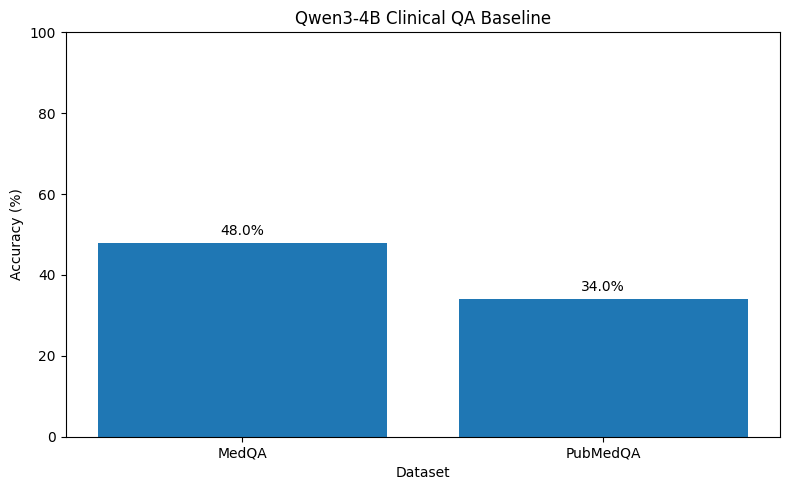

In [29]:
# Visualize the baseline Performance
import matplotlib.pyplot as plt

tasks = ["MedQA", "PubMedQA"]

accuracies = [
    medqa_metrics["accuracy"] * 100,
    pubmed_metrics["accuracy"] * 100
]

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(tasks, accuracies)

ax.set_title("Qwen3-4B Clinical QA Baseline")
ax.set_xlabel("Dataset")
ax.set_ylabel("Accuracy (%)")
ax.set_ylim(0, 100)

for bar, accuracy in zip(bars, accuracies):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 2,
        f"{accuracy:.1f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()

In [30]:
# Save the baseline evaluation results
import json

medqa_results.to_csv(
    RESULTS_DIR / "medqa_predictions.csv",
    index=False
)

pubmed_results.to_csv(
    RESULTS_DIR / "pubmedqa_predictions.csv",
    index=False
)

baseline_summary = {
    "model": MODEL_ID,
    "training_dataset": "MedQA + PubMedQA",
    "quantization": "NF4 4-bit",
    "thinking_enabled": False,
    "decoding": "greedy",
    "max_new_tokens": 24,
    "max_context": MAX_CONTEXT,
    "seed": SEED,
    "evaluation_split": "validation",
    "medqa": medqa_metrics,
    "pubmedqa": pubmed_metrics,
    "macro_accuracy": float(macro_accuracy),
    "gpu": torch.cuda.get_device_name(0),
}

with open(
    RESULTS_DIR / "baseline_metrics.json",
    "w"
) as file:
    json.dump(baseline_summary, file, indent=4)

print("Baseline evaluation saved successfully!")

print("\nSaved files:")
print(RESULTS_DIR / "medqa_predictions.csv")
print(RESULTS_DIR / "pubmedqa_predictions.csv")
print(RESULTS_DIR / "baseline_metrics.json")


Baseline evaluation saved successfully!

Saved files:
/content/drive/MyDrive/clinical-qa-finetuning-v2/results/baseline/medqa_predictions.csv
/content/drive/MyDrive/clinical-qa-finetuning-v2/results/baseline/pubmedqa_predictions.csv
/content/drive/MyDrive/clinical-qa-finetuning-v2/results/baseline/baseline_metrics.json
